# Day 6 — Image Preprocessing, Augmentation, Convolution & CNN Basics
**System 7 · Week 3 · Commit: `day-20-cnn-basics`**

**Module D:** image data and preprocessing, resizing, normalisation, augmentation, convolution, filters, pooling, feature maps, CNN basics.

**Practice questions solved today:** Q16, Q17 · **Learning topic:** Why CNNs suit images

In [1]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings, random, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.signal import convolve2d
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
warnings.filterwarnings("ignore")
RANDOM_STATE = 42; keras.utils.set_random_seed(RANDOM_STATE); R = {}
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

I0000 00:00:1793517104.657478   11036 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793517105.835087   11036 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Dataset — CIFAR-10
60,000 colour images, **32 × 32 pixels**, 10 classes (50,000 train / 10,000 test). Each image is a 3-D array `height × width × 3 channels (RGB)` of integers 0–255.

Data source: offline copy of CIFAR-10 images
train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3) | pixel range: 0 - 255
Images per class (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


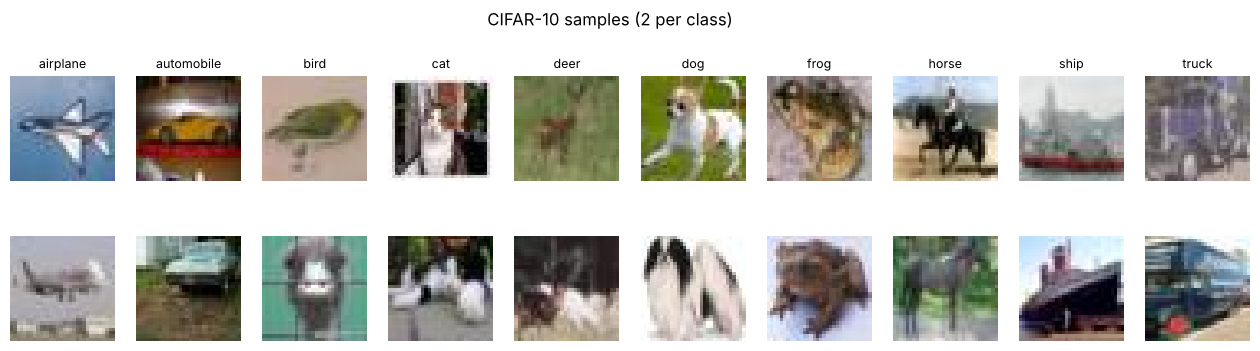

In [2]:
try:
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()          # normal route (needs internet)
    y_train, y_test = y_train.ravel(), y_test.ravel(); source = "keras.datasets.cifar10"
except Exception as e:                                                                  # offline copy of the same dataset
    d = np.load("/home/claude/data/cifar10.npz"); x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    perm = np.random.default_rng(RANDOM_STATE).permutation(len(x_train)); x_train, y_train = x_train[perm], y_train[perm]; source = "offline copy of CIFAR-10 images"
print("Data source:", source); print("train:", x_train.shape, x_train.dtype, "| test:", x_test.shape, "| pixel range:", x_train.min(), "-", x_train.max())
print("Images per class (train):", np.bincount(y_train))

fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for c in range(10):
    for r in range(2): axes[r, c].imshow(x_train[np.where(y_train == c)[0][r]]); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle("CIFAR-10 samples (2 per class)", y=1.02); plt.show()

## Q16 (Medium) — Resize to 64×64, normalise, augment, display 9 augmented samples
* **Resizing** gives every image the same size (networks need a fixed input shape); larger inputs keep more detail but cost more compute.
* **Normalising** pixels from 0–255 to **0–1** keeps inputs small and on a common scale, so gradient descent is stable.
* **Augmentation** randomly flips / rotates / zooms / shifts / changes contrast of *training* images, creating new plausible variants. It acts as a regulariser against overfitting. It must **never** be applied to validation/test data.

Before: (64, 32, 32, 3), range [0, 255]  ->  After: (64, 64, 64, 3), range [0.00, 1.00]


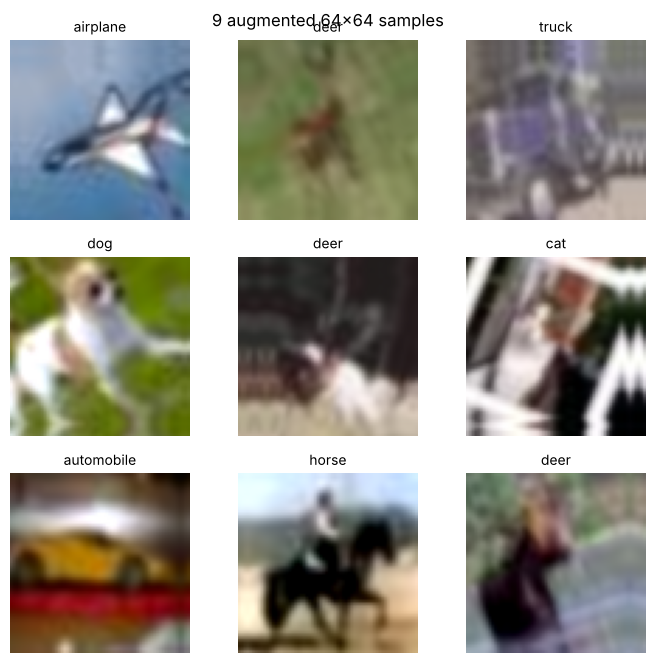

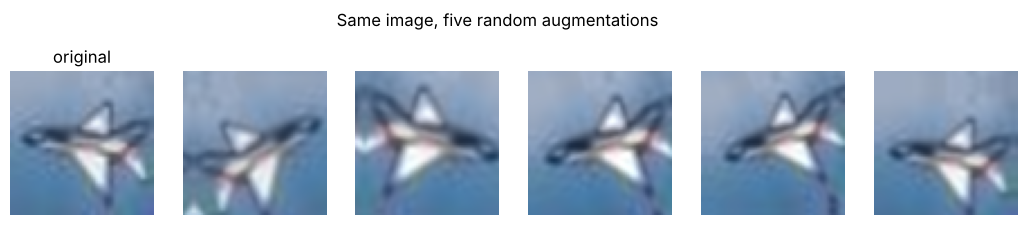

In [3]:
batch = x_train[:64].astype("float32")
resized = tf.image.resize(batch, (64, 64), method="bilinear")           # 32x32 -> 64x64
normalized = resized / 255.0                                            # 0-255 -> 0-1
print(f"Before: {batch.shape}, range [{batch.min():.0f}, {batch.max():.0f}]  ->  After: {normalized.shape}, range [{normalized.numpy().min():.2f}, {normalized.numpy().max():.2f}]")

augment = keras.Sequential([
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1), layers.RandomContrast(0.2)], name="augmentation")

fig, axes = plt.subplots(3, 3, figsize=(7, 7)); keras.utils.set_random_seed(3)
for i, ax in enumerate(axes.ravel()):
    img = augment(normalized[i:i+1], training=True)[0].numpy().clip(0, 1)      # training=True turns the random layers ON
    ax.imshow(img); ax.set_title(CLASSES[y_train[i]], fontsize=10); ax.axis("off")
plt.suptitle("9 augmented 64×64 samples", y=.94); plt.tight_layout(); plt.show()

# one image, many augmentations
fig, axes = plt.subplots(1, 6, figsize=(13, 2.4)); axes[0].imshow(normalized[0]); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]: ax.imshow(augment(normalized[:1], training=True)[0].numpy().clip(0, 1)); ax.axis("off")
plt.suptitle("Same image, five random augmentations", y=1.05); plt.show()
R["q16"] = {"before_shape": list(batch.shape), "after_shape": list(normalized.shape), "range_after": [0.0, 1.0], "layers": [l.__class__.__name__ for l in augment.layers]}

## Convolution, filters, pooling and feature maps
A **convolution** slides a small filter (e.g. 3×3) over the image; at each position it multiplies the filter with the pixels underneath and sums them. Different filters detect different things (edges, blur, corners). In a CNN the filter values are **learned** rather than hand-designed. The output is a **feature map** showing where that pattern appears.

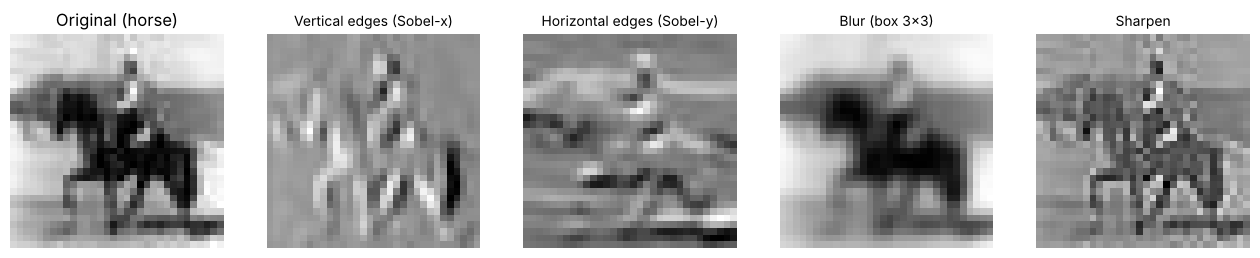

Feature map 4×4:
 [[1 3 2 1]
 [4 6 5 0]
 [7 2 9 8]
 [3 1 4 6]] 

After 2×2 max-pooling (2×2):
 [[6 5]
 [7 9]]

Same result with Keras MaxPooling2D: [[6, 5], [7, 9]]


In [4]:
img = tf.image.rgb_to_grayscale(x_train[7:8].astype("float32"))[0, :, :, 0].numpy() / 255
kernels = {"Vertical edges (Sobel-x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
           "Horizontal edges (Sobel-y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
           "Blur (box 3×3)": np.ones((3, 3)) / 9, "Sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4)); axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"Original ({CLASSES[y_train[7]]})")
for ax, (n, k) in zip(axes[1:], kernels.items()): ax.imshow(convolve2d(img, k, mode="same", boundary="symm"), cmap="gray"); ax.set_title(n, fontsize=10)
for ax in axes: ax.axis("off")
plt.show()

# max pooling by hand: 2x2 window, stride 2 keeps the strongest response and halves width/height
fm = np.array([[1, 3, 2, 1], [4, 6, 5, 0], [7, 2, 9, 8], [3, 1, 4, 6]])
pooled = fm.reshape(2, 2, 2, 2).max(axis=(1, 3))
print("Feature map 4×4:\n", fm, "\n\nAfter 2×2 max-pooling (2×2):\n", pooled)
print("\nSame result with Keras MaxPooling2D:", keras.layers.MaxPooling2D(2)(fm.reshape(1, 4, 4, 1).astype("float32")).numpy().reshape(2, 2).astype(int).tolist())

Pooling shrinks the feature maps (less computation), and makes the network tolerant to small shifts of the object, because only the strongest response in each window survives.

## Learning topic — Why CNNs suit images
A fully connected (dense) layer treats every pixel as an unrelated input, so it needs one weight for *every pixel–neuron pair*, ignores that neighbouring pixels belong together, and must re-learn the same pattern at every location. A convolutional layer instead uses
* **local filters** — each neuron looks at a small neighbourhood (edges, textures are local),
* **weight sharing** — the same filter is reused at every position, so it detects a pattern *wherever* it appears (translation equivariance) with very few parameters,
* **hierarchy** — early layers learn edges, middle layers textures/parts, deep layers whole objects.

Parameter comparison for one layer on a 32×32×3 image:

In [5]:
inp = layers.Input((32, 32, 3))
dense_layer = keras.Model(inp, layers.Dense(32)(layers.Flatten()(inp)))             # 32 neurons seeing every pixel
conv_layer  = keras.Model(inp, layers.Conv2D(32, 3, padding="same")(inp))           # 32 filters of 3x3x3
print(f"Dense(32) on flattened image : {dense_layer.count_params():>8,} parameters")
print(f"Conv2D(32 filters, 3×3)      : {conv_layer.count_params():>8,} parameters   (and it keeps the spatial layout: output 32×32×32)")
R["param_compare"] = {"dense": int(dense_layer.count_params()), "conv": int(conv_layer.count_params())}

Dense(32) on flattened image :   98,336 parameters
Conv2D(32 filters, 3×3)      :      896 parameters   (and it keeps the spatial layout: output 32×32×32)


---
## Q17 (Hard) — CNN with Conv2D and MaxPooling for CIFAR-10: test accuracy + confusion matrix
**Architecture:** three blocks of `Conv2D → BatchNorm → (Conv2D → BatchNorm) → MaxPooling → Dropout` with 32, 64, 128 filters (`relu`), then `Flatten → Dense(128) → Dropout → Dense(10, softmax)`.
Flip + small-shift augmentation is built into the model (active only while training). 5,000 training images are held out for validation; the 10,000 test images are used **once** at the end.

In [6]:
def conv_block(f, two=True):
    L = [layers.Conv2D(f, 3, padding="same", activation="relu"), layers.BatchNormalization()]
    if two: L += [layers.Conv2D(f, 3, padding="same", activation="relu"), layers.BatchNormalization()]
    return L + [layers.MaxPooling2D(2), layers.Dropout(0.25)]

keras.utils.set_random_seed(RANDOM_STATE)
cnn = keras.Sequential([layers.Input((32, 32, 3)), layers.Rescaling(1/255),
                        layers.RandomFlip("horizontal"), layers.RandomTranslation(0.08, 0.08)]
                       + conv_block(32, False) + conv_block(64) + conv_block(128)
                       + [layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dropout(0.4), layers.Dense(10, activation="softmax")], name="cifar_cnn")
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "cifar_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             

 Total params: 542,986 (2.07 MB)

 Trainable params: 542,154 (2.07 MB)

 Non-trainable params: 832 (3.25 KB)

In [7]:
cb = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=.5, patience=2, verbose=0), keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)]
t0 = time.time()
hist = cnn.fit(x_train, y_train, validation_split=0.1, epochs=12, batch_size=64, callbacks=cb, verbose=2)
train_time = time.time() - t0; print(f"\nTraining time: {train_time/60:.1f} min")
cnn.save("cnn_cifar10.keras")

Epoch 1/12


704/704 - 88s - 125ms/step - accuracy: 0.3571 - loss: 1.7750 - val_accuracy: 0.4582 - val_loss: 1.4818 - learning_rate: 0.0010


Epoch 2/12


704/704 - 139s - 198ms/step - accuracy: 0.4785 - loss: 1.4475 - val_accuracy: 0.5180 - val_loss: 1.3855 - learning_rate: 0.0010


Epoch 3/12


704/704 - 142s - 201ms/step - accuracy: 0.5446 - loss: 1.2787 - val_accuracy: 0.6012 - val_loss: 1.1058 - learning_rate: 0.0010


... (15 outputs left out)

704/704 - 141s - 201ms/step - accuracy: 0.7329 - loss: 0.7774 - val_accuracy: 0.7638 - val_loss: 0.6826 - learning_rate: 5.0000e-04


Epoch 12/12


704/704 - 84s - 119ms/step - accuracy: 0.7407 - loss: 0.7528 - val_accuracy: 0.7692 - val_loss: 0.6851 - learning_rate: 5.0000e-04



Training time: 25.5 min


TEST accuracy: 0.7681 | TEST loss: 0.6746
              precision    recall  f1-score   support

    airplane      0.795     0.796     0.796      1000
  automobile      0.879     0.928     0.903      1000
        bird      0.757     0.591     0.664      1000
         cat      0.593     0.556     0.574      1000
        deer      0.793     0.626     0.700      1000
         dog      0.599     0.738     0.661      1000
        frog      0.715     0.905     0.799      1000
       horse      0.840     0.785     0.812      1000
        ship      0.859     0.899     0.878      1000
       truck      0.895     0.857     0.875      1000

    accuracy                          0.768     10000
   macro avg      0.773     0.768     0.766     10000
weighted avg      0.773     0.768     0.766     10000



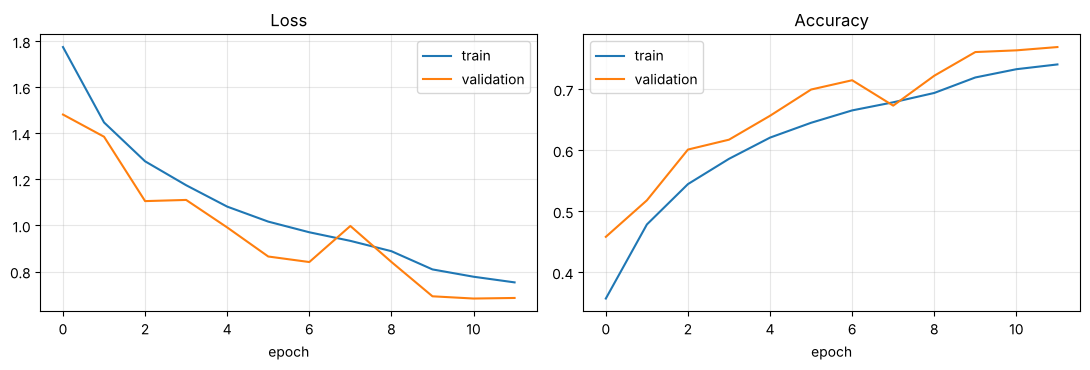

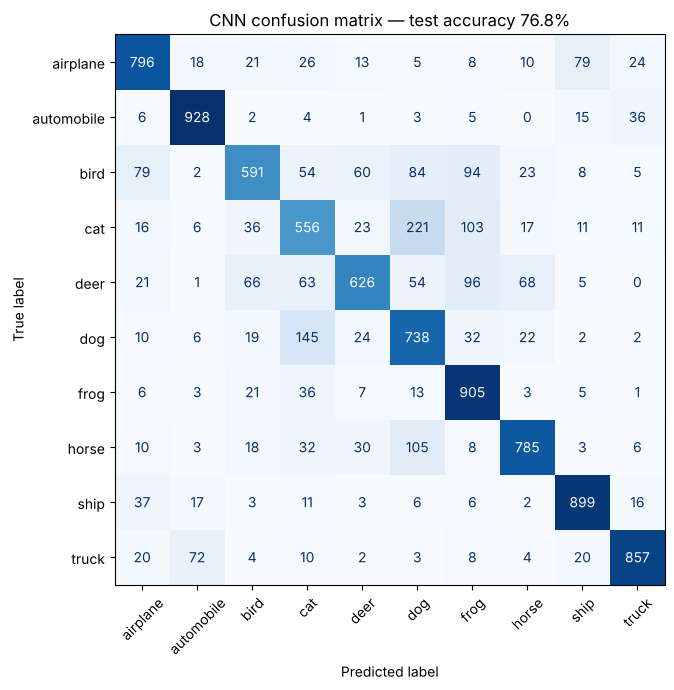

Easiest class: automobile (92.8%) | Hardest class: cat (55.6%)
Most common confusion: true 'cat' predicted as 'dog' (221 images)


In [8]:
test_loss, test_acc = cnn.evaluate(x_test, y_test, verbose=0)
y_prob = cnn.predict(x_test, verbose=0); y_pred = y_prob.argmax(1)
print(f"TEST accuracy: {test_acc:.4f} | TEST loss: {test_loss:.4f}")
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); h = hist.history
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set(title="Loss", xlabel="epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set(title="Accuracy", xlabel="epoch"); ax[1].legend(); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 7)); ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False); ax.set_title(f"CNN confusion matrix — test accuracy {test_acc:.1%}"); plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(1); order = np.argsort(per_class)
off = cm.copy(); np.fill_diagonal(off, 0); a, b = np.unravel_index(off.argmax(), off.shape)
print(f"Easiest class: {CLASSES[order[-1]]} ({per_class[order[-1]]:.1%}) | Hardest class: {CLASSES[order[0]]} ({per_class[order[0]]:.1%})")
print(f"Most common confusion: true '{CLASSES[a]}' predicted as '{CLASSES[b]}' ({off[a, b]} images)")
R["q17"] = {"test_acc": round(float(test_acc), 4), "test_loss": round(float(test_loss), 4), "epochs_run": len(h["loss"]), "params": int(cnn.count_params()), "train_minutes": round(train_time/60, 1),
            "best_class": [CLASSES[order[-1]], round(float(per_class[order[-1]]), 3)], "worst_class": [CLASSES[order[0]], round(float(per_class[order[0]]), 3)],
            "top_confusion": [CLASSES[a], CLASSES[b], int(off[a, b])], "final_train_acc": round(h["accuracy"][-1], 4), "final_val_acc": round(h["val_accuracy"][-1], 4), "source": source}

**Reading the results:** accuracy is far above the 10 % of random guessing. Mistakes concentrate in **visually similar classes** — see the printed hardest class and most common confusion, and the largest off-diagonal cells in the matrix. The train/validation curves stay close together, thanks to dropout, batch-norm and augmentation, so the model is not badly overfitting. Day 7 compares this from-scratch CNN with transfer learning.

## What the CNN actually learned — feature maps
The first-layer filters and their feature maps for one test image (early layers respond to edges and colours):

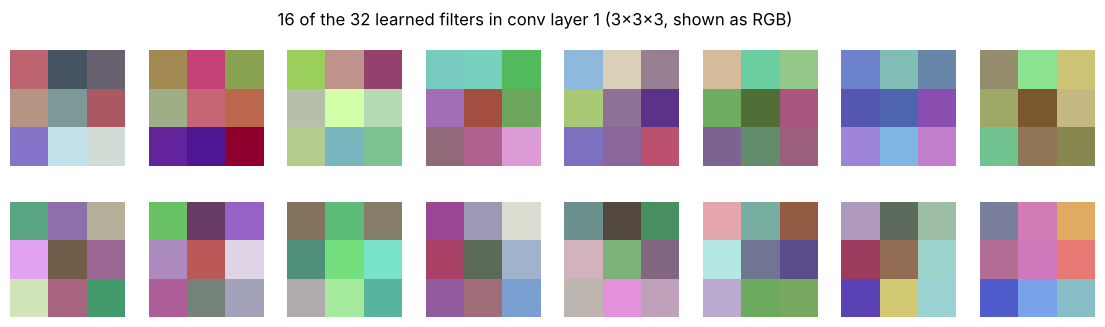

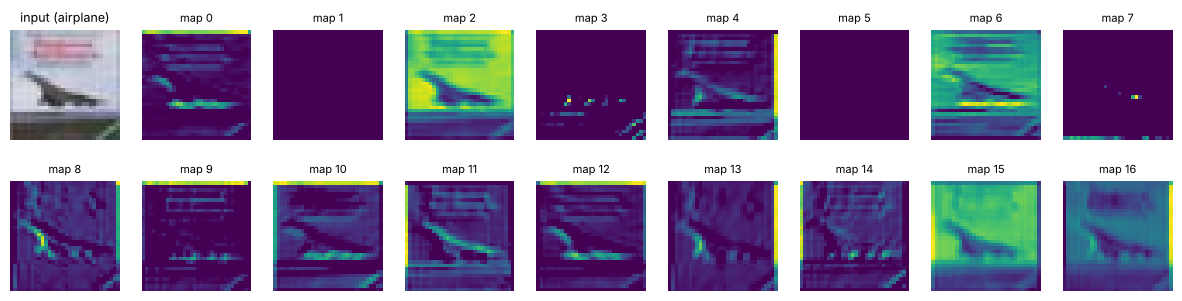

In [9]:
first_conv = [l for l in cnn.layers if isinstance(l, layers.Conv2D)][0]
W = first_conv.get_weights()[0]; w_min, w_max = W.min(), W.max()
fig, axes = plt.subplots(2, 8, figsize=(14, 3.6))
for i, ax in enumerate(axes.ravel()): ax.imshow((W[:, :, :, i] - w_min) / (w_max - w_min)); ax.axis("off")
plt.suptitle("16 of the 32 learned filters in conv layer 1 (3×3×3, shown as RGB)"); plt.show()

sample = x_test[:1].astype("float32"); fm_model = keras.Model(cnn.inputs, first_conv.output)
fmaps = fm_model.predict(sample, verbose=0)[0]
fig, axes = plt.subplots(2, 9, figsize=(15, 3.6)); axes[0, 0].imshow(x_test[0]); axes[0, 0].set_title(f"input ({CLASSES[y_test[0]]})", fontsize=9)
for i, ax in enumerate(axes.ravel()[1:]): ax.imshow(fmaps[:, :, i], cmap="viridis"); ax.set_title(f"map {i}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.show()

### Summary of Day 6
| Topic | Takeaway |
|---|---|
| Preprocessing | Resize to a fixed shape, scale pixels to 0–1 |
| Augmentation | Random flips/rotations/zooms on training data only → less overfitting |
| Convolution | Learned local filters slide over the image → feature maps |
| Pooling | Downsamples, keeps strongest responses, adds shift tolerance |
| CNN vs dense | Far fewer parameters, spatial structure preserved |

In [10]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
